# 13-2. 선정 모델의 origin별 예측구간 PNG 저장

`13-1`의 점선 그래프를 모든 origin마다 그려 변수명 폴더에 PNG로 저장한다. 계산과 그림이 함수로 나뉘어 있어 `SEL`(변수별 선정 모델)에 변수를 넣고 `save_variable(변수명)`을 부르면 같은 그래프가 만들어진다.

- **함수**: `run_variable(v)`가 모든 origin의 구간과 7분위를 계산하고(12시리즈와 같은 방식, 같은 시드), `draw_origin`이 그림 한 장을, `save_variable`이 변수 전체를 저장한다.
- **저장 위치**: `예측구간_png/변수명(한글 변수명)/변수명_예측첫분기.png` (예: `X3_l1(X3)/X3_l1_2019Q4.png`)
- **제목**: 변수명(한글 변수명), 선정 모델, 예측분기
- **마지막 4개 origin**: 데이터가 끝나는 2025Q4 이후까지 예측하는 origin이라 실제값이 일부 또는 전부 없다. 구간은 만들고, 실제값이 있는 분기만 표시한다.

## 1. 구현

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean
from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- SV 동시 (QML + 칼만필터)
def is_ar_stable(lags, ar):
    if not len(lags):
        return True
    mx = max(lags)
    a = np.zeros(mx)
    for l, c in zip(lags, ar):
        a[l - 1] = c
    comp = np.zeros((mx, mx))
    comp[0, :] = a
    if mx > 1:
        comp[1:, :-1] = np.eye(mx - 1)
    return np.max(np.abs(np.linalg.eigvals(comp))) < 0.999


def sv_residuals(w, lags, ar, c):
    mx = max(lags) if len(lags) else 0
    return np.array([w[t] - c - sum(a * w[t - l] for a, l in zip(ar, lags)) for t in range(mx, len(w))])


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def _unpack(params, k, const):
    ar = params[:k]
    c = params[k] if const else 0.0
    j = k + (1 if const else 0)
    return ar, c, MAX_PHI * np.tanh(params[j]), np.exp(params[j + 1]) ** 2


def joint_sv_negloglik(params, w, lags, const):
    ar, c, phi, s2 = _unpack(params, len(lags), const)
    if not is_ar_stable(lags, ar):
        return 1e10
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, sp, lags):
    w = difference(train, sp)
    k = len(lags)
    x0 = [0.0] * k + ([float(np.mean(w))] if sp.const else []) + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(w, lags, sp.const), method="Nelder-Mead", options={"maxiter": 3000})
    ar, c, phi, s2 = _unpack(res.x, k, sp.const)
    if not is_ar_stable(lags, ar) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(w[-max(lags):]) if k else []
    mean_w = []
    for _ in range(H):
        pred = c + sum(a * past[-l] for a, l in zip(ar, lags))
        mean_w.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** j * hf + (phi ** (2 * j) * Pf + s2 * sum(phi ** (2 * i) for i in range(j))) / 2) for j in range(1, H + 1)]
    fc, sig = undiff(mean_w, train, sp), level_sigma(lags, ar, sp, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- 공용 진입점
def forecast(model, train, sp=Spec()):
    """model: 'AR단독' | 'GARCH' | 'SV'. 반환: (예측 4개, σ 4개, 사용한 모델, (p, P)). 적합 실패 시 NaN을 돌려준다(src='실패')."""
    p, P, m = select_structure(train, sp)
    if model == "AR단독":
        fc, sig = ar_forecast(m)
        return fc, sig, "AR단독", (p, P)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = (garch_forecast if model == "GARCH" else sv_forecast)(train, sp, lags)
        return fc, sig, model, (p, P)
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, "실패", (p, P)


## 2. 계산과 그림 함수

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
NAMES = {"X3_l1": "X3", "X6_l1": "X6", "X2": "X2",
         "X1_l1": "X1", "X5_l1": "X5", "X4": "X4"}
# 변수별 선정 모델 (모델, d, D, 스케일, 구간). 다른 변수나 다른 모델을 보려면 여기만 바꾸면 된다.
SEL = {"X3_l1": ("GARCH", 1, 0, "원", "리샘플링"), "X6_l1": ("SV", 1, 0, "원", "자체"), "X2": ("AR단독", 0, 0, "원", "자체"),
       "X1_l1": ("GARCH", 0, 0, "원", "리샘플링"), "X5_l1": ("GARCH", 0, 0, "로그", "자체"), "X4": ("GARCH", 0, 0, "원", "리샘플링")}
CACHE_NO = {"X3_l1": 15, "X6_l1": 7, "X2": 8, "X1_l1": 9, "X5_l1": 10, "X4": 11}
SCALE, N_ENS, MIN_TRAIN, INITIAL_CALIB, N_HIST = 100.0, 500, 20, 15, 8
SEED = 42                                                                  # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
TAUS = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]
TAU_COLOR = {0.1: "#CC79A7", 0.9: "#CC79A7", 0.2: "#009E73", 0.8: "#009E73", 0.3: "#56B4E9", 0.7: "#56B4E9", 0.5: "#6B7280"}
OUT_DIR = "예측구간_png"                                                          # 변수명(한글 변수명) 폴더가 이 안에 만들어진다


def next_quarter(lab):
    y_, q_ = int(lab[:4]), int(lab[5])
    return f"{y_ + (q_ == 4)}Q{q_ % 4 + 1}"


def run_variable(v):
    """변수 v의 선정 모델로 모든 채점 origin의 예측구간(90%)과 7분위를 계산한다. 12시리즈와 같은 방식, 같은 시드."""
    model, d, D, sc, iv = SEL[v]
    sp, logm, std = Spec(d=d, D=D), sc == "로그", model != "AR단독"
    s_ = raw[["quarter", v]].dropna().reset_index(drop=True)
    y0, q = s_[v].values.astype(float), s_["quarter"].values
    vals = y0
    var_std = y0.std()                                                          # 점수 정규화 단위(원래 단위)


    def ser(o):                                                                 # origin o의 단위 상수(훈련 구간 표준편차 기준)와 모델 입력 계열
        C = 100 / vals[:o].std()
        return C, (SCALE * np.log(vals * C) if logm else vals * C)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logm else (lambda x: np.asarray(x))
    qfull = list(q)
    while len(qfull) < len(vals) + H:
        qfull.append(next_quarter(qfull[-1]))                                   # 데이터 이후의 예측 분기 이름
    rng = np.random.default_rng(SEED)
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    n = len(vals)
    for oi, o in enumerate(range(MIN_TRAIN, n + 1)):                              # 데이터 끝까지의 모든 origin(마지막 4개는 실제값이 일부 또는 전부 없음)
        C, series = ser(o)
        fc, sig, src, _ = forecast(model, series[:o], sp)
        if oi >= INITIAL_CALIB:                                                  # 구간을 만드는 origin(채점은 실제값이 있는 분기만)
            for h in range(1, H + 1):
                s_h = max(sig[h - 1], 1e-6)
                if iv == "자체":
                    lo, hi = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
                    qs = tf(fc[h - 1] + s_h * stats.norm.ppf(TAUS))
                else:
                    pool = np.array([e for o2, e in errs[h] if o2 + h <= o]) * (C if (not std and not logm) else 1)      # 정답이 확정된 오차만
                    samples = fc[h - 1] + (s_h if std else 1.0) * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                    lo, hi = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                    qs = tf(np.quantile(samples, TAUS))
                lo, hi, qs = lo / C, hi / C, np.asarray(qs) / C                       # 원래 단위로 되돌린다
                known = o + h - 1 < n                                                 # 실제값이 있는 분기인가
                a = vals[o + h - 1] if known else np.nan
                rows.append({"origin": o, "h": h, "분기": qfull[o + h - 1], "하한": float(lo), "상한": float(hi), "실제": a, "적중": float(lo <= a <= hi) if known else np.nan,
                             "폭_정규화": float((hi - lo) / var_std), **{f"q{int(round(tt * 100))}": float(x) for tt, x in zip(TAUS, qs)}})
        for h in range(1, H + 1):
            if o + h - 1 < n:                                                       # 정답이 있는 오차만 풀에 쌓는다
                e = series[o + h - 1] - fc[h - 1]
                errs[h].append((o, e / max(sig[h - 1], 1e-6) if std else e / (1 if logm else C)))
    return pd.DataFrame(rows), dict(q=np.array(qfull), y=y0)


def draw_origin(v, o, t, info):
    """origin o의 예측구간 그래프(점선 표시)를 그려 Figure를 돌려준다."""
    q, y = info["q"], info["y"]
    model, d, D, sc, iv = SEL[v]
    k0, k = o - N_HIST, np.arange(o - N_HIST, o + H)
    fk = np.arange(o, o + H)
    xs, last = np.r_[o - 1, fk], y[o - 1]
    fig, ax = plt.subplots(figsize=(9, 5.8))
    ax.plot(k[:N_HIST], y[k0:o], color="#172033", linewidth=2)                                             # 예측 시점 전 8분기
    ax.fill_between(xs, np.r_[last, t["하한"].values], np.r_[last, t["상한"].values], color="#0072B2", alpha=0.10)   # 90% 구간
    for tt in TAUS:                                                                                         # 7분위 점선
        col, key = TAU_COLOR[tt], f"q{int(round(tt * 100))}"
        ax.plot(xs, np.r_[last, t[key].values], color=col, linewidth=1.4, linestyle=(0, (1.5, 2)))
        ax.text(fk[-1] + 0.12, t[key].values[-1], f"{tt:g}", fontsize=8, color=col, va="center")
    ax.plot(np.r_[o - 1, fk], np.r_[last, t["실제"].values], color="#D55E00", linewidth=1.6, zorder=4)         # 실제값
    hit, miss = t["적중"].values == 1, t["적중"].values == 0                                              # 실제값이 없는 분기는 둘 다 아님
    ax.scatter(fk[hit], t["실제"].values[hit], color="#D55E00", s=70, zorder=5)
    ax.scatter(fk[miss], t["실제"].values[miss], color="#D55E00", marker="X", s=100, zorder=5)
    ax.axvline(o - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(k)
    ax.set_xticklabels(q[k], rotation=45, fontsize=9)
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)
    ax.set_title(f"{v} ({NAMES[v]})", fontsize=14.5, fontweight="bold", color="#172033", pad=44)            # 변수명은 크게
    ax.text(0.5, 1.012, f"{model}·({d},{D})·{sc}·{iv}\n예측분기: {q[o]} ~ {q[o + H - 1]}", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=10.5, color="#172033", linespacing=1.5)
    h_ = [Line2D([0], [0], color=col, linewidth=1.6, linestyle=(0, (1.5, 2)), label=f"분위수 {lab_}") for lab_, col in [("0.1 · 0.9", "#CC79A7"), ("0.2 · 0.8", "#009E73"), ("0.3 · 0.7", "#56B4E9"), ("0.5", "#6B7280")]]
    h_ += [Patch(color="#0072B2", alpha=0.2, label="90% 구간(5~95%)"), Line2D([0], [0], color="#D55E00", marker="o", linewidth=1.6, label="실제값(구간 안)"),
           Line2D([0], [0], color="#D55E00", marker="X", markersize=9, linewidth=1.6, label="실제값(구간 밖)")]
    fig.legend(handles=h_, loc="lower center", ncol=4, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    return fig


def save_variable(v, res=None):
    """변수 v의 모든 채점 origin 그래프를 OUT_DIR/변수명(한글 변수명)/ 에 PNG로 저장하고 파일 경로 목록을 돌려준다."""
    res, info = res if res is not None else run_variable(v)
    folder = os.path.join(OUT_DIR, f"{v}({NAMES[v]})")                                   # 폴더 이름: 변수명(한글 변수명)
    os.makedirs(folder, exist_ok=True)
    paths = []
    for o, t in res.groupby("origin"):
        t = t.sort_values("h")
        fig = draw_origin(v, o, t, info)
        p = os.path.join(folder, f"{v}_{t['분기'].iloc[0]}.png")                                  # 파일 이름: 변수명_예측 첫 분기
        fig.savefig(p, dpi=150)
        plt.close(fig)
        paths.append(p)
    return paths


## 3. 6개 변수 전체 저장

In [3]:
RES, PATHS = {}, {}
for v in SEL:
    RES[v] = run_variable(v)                       # (구간 표, 데이터 정보)
    PATHS[v] = save_variable(v, RES[v])
    print(f"{v}: PNG {len(PATHS[v])}개 저장 -> {os.path.join(OUT_DIR, f"{v}({NAMES[v]})")}")


X3_l1: PNG 26개 저장 -> 예측구간_png\X3_l1(X3)


X6_l1: PNG 29개 저장 -> 예측구간_png\X6_l1(X6)


X2: PNG 26개 저장 -> 예측구간_png\X2(X2)


X1_l1: PNG 25개 저장 -> 예측구간_png\X1_l1(X1)


X5_l1: PNG 25개 저장 -> 예측구간_png\X5_l1(X5)


X4: PNG 26개 저장 -> 예측구간_png\X4(X4)


## 4. 12시리즈 결과와 일치하는지 확인

채점 origin에서 적중 여부와 구간 폭이 캐시의 같은 조합과 같아야 한다(캐시에는 채점 origin만 있다).

In [4]:
rows = []
for v, (res, info) in RES.items():
    model, d, D, sc, iv = SEL[v]
    c = pd.read_pickle(f"../cache/cache_12{CACHE_NO[v]}_{v}_df.pkl" if v != "X3_l1" else "../cache/cache_1215_X3_l1_df.pkl")
    c = c[(c["모델"] == model) & (c["d"] == d) & (c["D"] == D) & (c["스케일"] == sc) & (c["구간"] == iv)].sort_values(["origin", "h"]).reset_index(drop=True)
    r_ = res[res["origin"].isin(c["origin"].unique())].sort_values(["origin", "h"]).reset_index(drop=True)          # 캐시에는 채점 origin만 있다
    rows.append({"변수": v, "비교한 origin 수": r_["origin"].nunique(), "전체 origin 수": res["origin"].nunique(), "행 수 일치": len(c) == len(r_), "적중 일치": bool((c["적중"].values == r_["적중"].values * 100).all()),
                 "폭 최대 차이": float(np.abs(c["폭"].values - r_["폭_정규화"].values).max())})
display(pd.DataFrame(rows).set_index("변수"))


,비교한 origin 수,전체 origin 수,행 수 일치,적중 일치,폭 최대 차이
변수,,,,,
X3_l1,22,26,True,True,0.0
X6_l1,25,29,True,True,0.0
X2,22,26,True,True,0.0
X1_l1,21,25,True,True,0.0
X5_l1,21,25,True,True,0.0
X4,22,26,True,True,0.0


## 5. 저장된 그림 예시 (X3의 첫 origin과 마지막 origin, 마지막은 실제값 없음)

예측구간_png\X3_l1(X3)\X3_l1_2019Q4.png


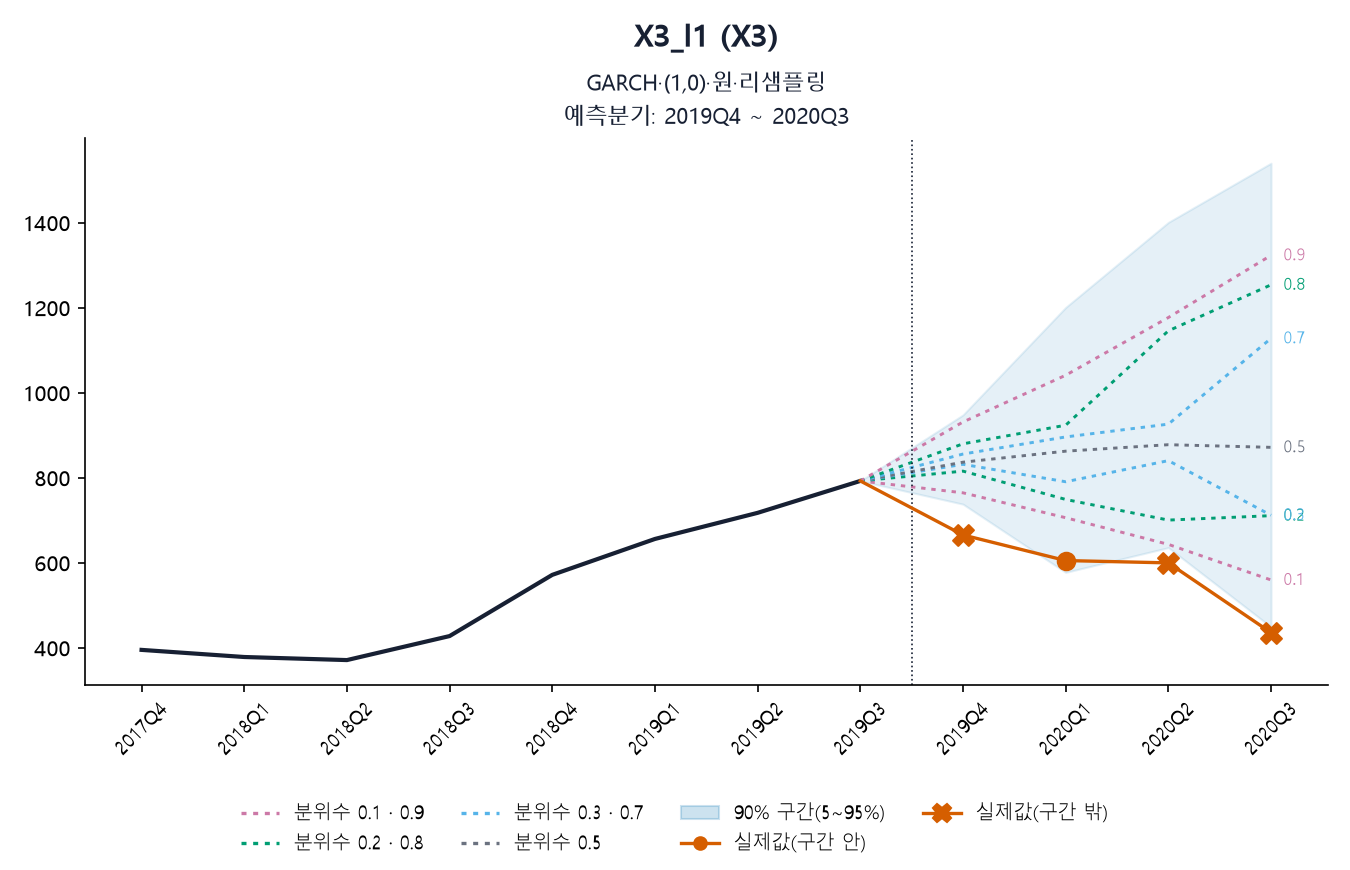

예측구간_png\X3_l1(X3)\X3_l1_2026Q1.png


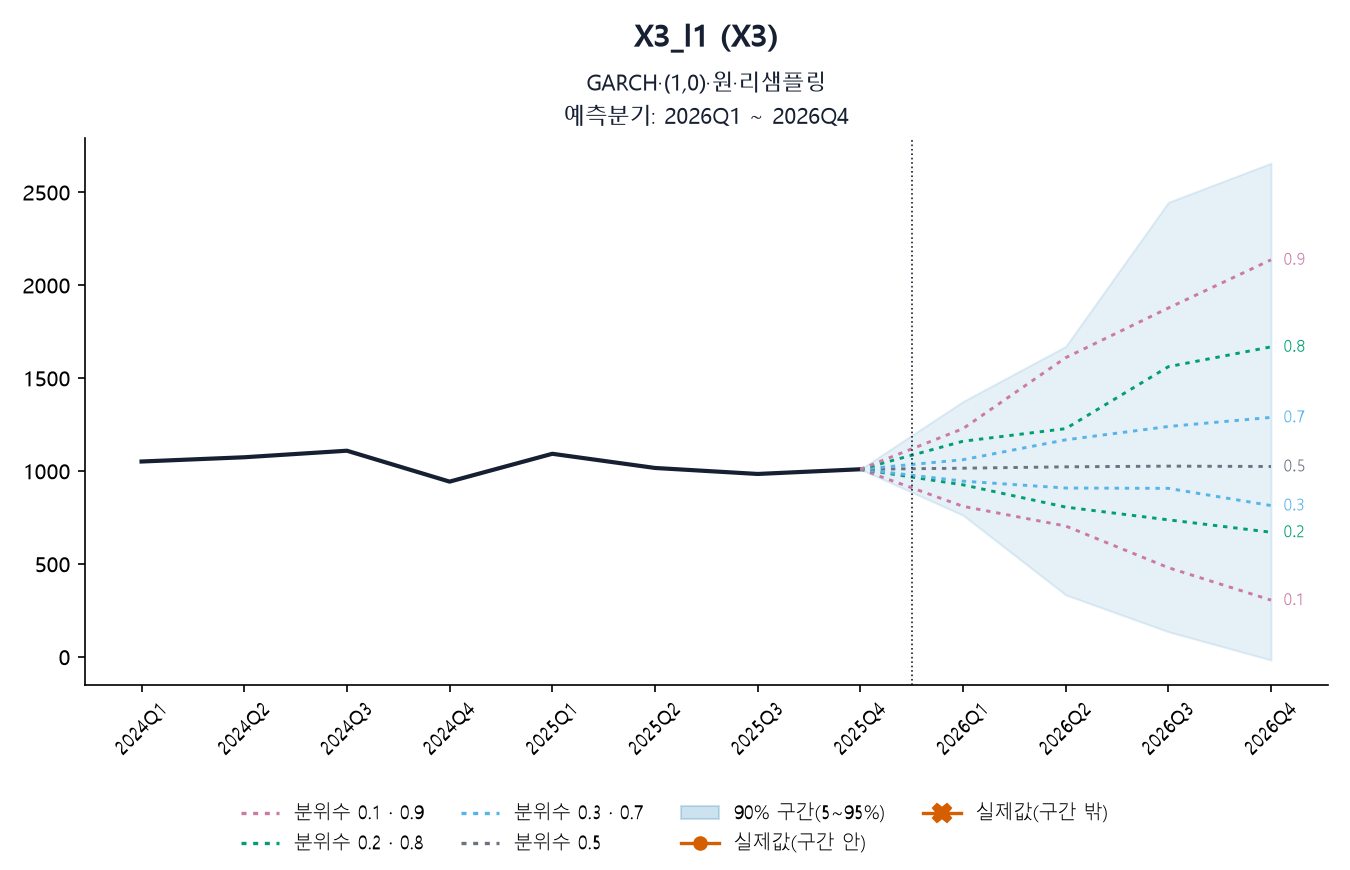

In [5]:
from IPython.display import Image, display
ps_ = PATHS["X3_l1"]
for p in (ps_[0], ps_[-1]):
    print(p)
    display(Image(filename=p, width=640))